# IDS por Anomalia para GOOSE (IEC 61850) com MLP e Random Forest
### Base para um IDS híbrido: anomalia (rede neural) + assinatura (regras geradas por LLM — SBRC 2026)

**Autor:** Lucas A. Martins — PPGEELT/UFU

Este notebook é a prova de conceito do módulo de **detecção por anomalia** de um IDS híbrido para tráfego GOOSE.
Ele treina e avalia dois algoritmos supervisionados sobre o dataset **ERENO** e, ao final, combina a saída do
modelo com as **regras de assinatura geradas por LLM** no trabalho do SBRC 2026 (`rules_llm_sbrc2026.py`).

| Seção | Conteúdo |
|---|---|
| §1 | Configuração do experimento (dataset e algoritmo) |
| §2 | Setup e dependências |
| §3 | Ingestão e limpeza do ERENO |
| §4 | Pré-processamento e divisão treino/teste |
| §5 | Treinamento (MLP e/ou Random Forest) |
| §6 | Teste do IDS: detecção de tráfego anômalo |
| §7 | Matrizes de confusão (multiclasse e binária) |
| §8 | Tráfego anômalo detectado por classe de ataque |
| §9 | Falhas de segurança do GOOSE exploradas e detectadas |
| §10 | Comparativo MLP × Random Forest (métricas e latência) |
| §11 | IDS híbrido: anomalia + regras LLM (SBRC 2026) |
| §12 | Exportação dos resultados |

> **Reprodutibilidade:** sementes fixas (`random_state=42`), divisão estratificada 70/30 e todos os resultados
> exportados para `resultados/`.

## §1 — Configuração do experimento
Defina **qual base de dados** será usada e **qual algoritmo** será treinado.
- `DATASET`: chave do dicionário `DATASETS` (o ERENO deve estar na pasta `dataset/`; `.csv` ou `.zip`).
- `ALGORITMO`: `"MLP"`, `"RF"` ou `"AMBOS"` (treina os dois e gera o comparativo).
- `CONJUNTO_ATRIBUTOS`: `"protocolo_eletrico"` (padrão, sem carimbos de tempo absolutos) ou `"protocolo"`
  (somente os campos GOOSE usados nas regras do SBRC 2026).

Opcionalmente, execute a célula de *widgets* logo abaixo para escolher pelos menus.

In [1]:
# ======================= CONFIGURAÇÃO =======================
DATASETS = {
    "ERENO-2.0-100K": "dataset/ERENO-2.0-100K.csv",   # aceita também dataset/ERENO-2.0-100K.zip
    # "Outro dataset":  "dataset/outro.csv",
}
DATASET            = "ERENO-2.0-100K"
ALGORITMO          = "AMBOS"            # "MLP" | "RF" | "AMBOS"
CONJUNTO_ATRIBUTOS = "protocolo_eletrico"  # "protocolo_eletrico" | "protocolo"
TEST_SIZE          = 0.30
RANDOM_STATE       = 42
USAR_REGRAS_LLM    = True               # §11: combina com rules_llm_sbrc2026.py, se existir
ARQUIVO_REGRAS     = "rules_llm_sbrc2026.py"
LIMIAR_FPR_REGRA   = 0.005              # §11: regra só entra na fusão seletiva se FPR em 'normal' (treino) ≤ 0,5%

# Hiperparâmetros
MLP_PARAMS = dict(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                  alpha=1e-4, batch_size=256, learning_rate_init=1e-3, max_iter=200,
                  early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                  random_state=RANDOM_STATE)
RF_PARAMS  = dict(n_estimators=100, criterion="gini", max_depth=None, min_samples_leaf=1,
                  n_jobs=-1, random_state=RANDOM_STATE)

In [2]:
# (Opcional) seleção interativa — requer ipywidgets. Pode pular esta célula.
try:
    import ipywidgets as w
    from IPython.display import display
    dd_ds  = w.Dropdown(options=list(DATASETS), value=DATASET, description="Dataset:")
    dd_alg = w.Dropdown(options=["MLP", "RF", "AMBOS"], value=ALGORITMO, description="Algoritmo:")
    dd_att = w.Dropdown(options=["protocolo_eletrico", "protocolo"], value=CONJUNTO_ATRIBUTOS,
                        description="Atributos:")
    def _upd(_):
        global DATASET, ALGORITMO, CONJUNTO_ATRIBUTOS
        DATASET, ALGORITMO, CONJUNTO_ATRIBUTOS = dd_ds.value, dd_alg.value, dd_att.value
        print(f"Selecionado -> dataset={DATASET} | algoritmo={ALGORITMO} | atributos={CONJUNTO_ATRIBUTOS}")
    for d in (dd_ds, dd_alg, dd_att): d.observe(_upd, names="value")
    display(w.VBox([dd_ds, dd_alg, dd_att])); _upd(None)
except ImportError:
    print("ipywidgets não instalado — usando os valores definidos na célula anterior.")

ipywidgets não instalado — usando os valores definidos na célula anterior.


## §2 — Setup

In [3]:
import os, time, json, importlib.util, inspect, warnings
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report, f1_score)
warnings.filterwarnings("ignore")
np.random.seed(RANDOM_STATE)

OUT_FIG, OUT_DAT = "resultados/figuras", "resultados/dados"
os.makedirs(OUT_FIG, exist_ok=True); os.makedirs(OUT_DAT, exist_ok=True)
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# Paleta categórica fixa (ordem nunca reciclada); 'normal' em cinza neutro
ATTACKS = ["grayhole", "high_StNum", "injection", "inverse_replay", "masquerade_fake_fault",
           "masquerade_fake_normal", "poisoned_high_rate", "random_replay"]
CLASSES = ["normal"] + ATTACKS
PALETTE = dict(zip(ATTACKS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                             "#e87ba4", "#008300", "#6250d6", "#e34948"]))
PALETTE["normal"] = "#8a8984"
MODEL_COLOR = {"MLP": "#2a78d6", "RF": "#eb6834", "Regras LLM": "#1baf7a", "Híbrido": "#6250d6"}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})
def salvar(fig, nome):
    fig.savefig(f"{OUT_FIG}/{nome}.png", bbox_inches="tight"); fig.savefig(f"{OUT_FIG}/{nome}.pdf", bbox_inches="tight")
print("Setup OK | sklearn + pandas", pd.__version__)

Setup OK | sklearn + pandas 3.0.5


## §3 — Ingestão e limpeza do ERENO
O arquivo `ERENO-2.0-100K.csv` contém 200.052 linhas e 52 colunas. Há 54 linhas de cabeçalho ARFF
(`@relation`, `@attribute`) concatenadas no meio do arquivo, que são removidas. As colunas categóricas
(`ethSrc`, `ethDst`, `goID`, `gocbRef` etc.) são constantes no ERENO e não carregam informação discriminante.

Lido: dataset/ERENO-2.0-100K.csv | shape bruto = (200052, 52) | 2.9s


Linhas de cabeçalho ARFF removidas: 54 | shape limpo = (199998, 52)
Colunas categóricas constantes descartadas (11): ['ethDst', 'ethSrc', 'ethType', 'gooseAppid', 'TPID', 'gocbRef', 'datSet', 'goID', 'test', 'ndsCom', 'protocol']


,amostras
class,
normal,39999
grayhole,19999
high_StNum,20000
injection,20000
inverse_replay,20000
masquerade_fake_fault,20000
masquerade_fake_normal,20000
poisoned_high_rate,20000
random_replay,20000


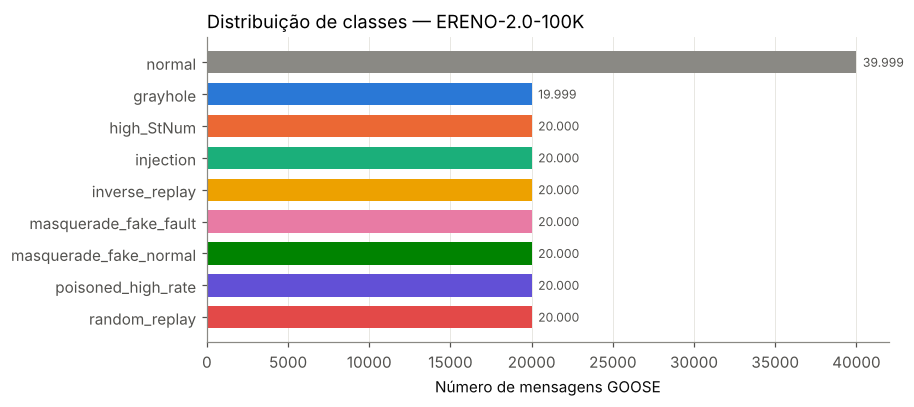

In [4]:
path = DATASETS[DATASET]
if not os.path.exists(path) and os.path.exists(path.replace(".csv", ".zip")):
    path = path.replace(".csv", ".zip")
t0 = time.time()
raw = pd.read_csv(path, low_memory=False)
print(f"Lido: {path} | shape bruto = {raw.shape} | {time.time()-t0:.1f}s")

df = raw.copy()
df["class"] = df["class"].astype(str).str.strip()
df["Time"] = pd.to_numeric(df["Time"], errors="coerce")
n_ruido = int(df["Time"].isna().sum())
df = df.dropna(subset=["Time"]).reset_index(drop=True)
cat_cols = [c for c in df.columns if c != "class" and pd.to_numeric(df[c], errors="coerce").isna().all()]
const_cat = [c for c in cat_cols if df[c].nunique() <= 1]
num_cols = [c for c in df.columns if c not in cat_cols + ["class"]]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce").astype(float)
print(f"Linhas de cabeçalho ARFF removidas: {n_ruido} | shape limpo = {df.shape}")
print(f"Colunas categóricas constantes descartadas ({len(const_cat)}): {const_cat}")
dist = df["class"].value_counts().reindex(CLASSES)
display(dist.to_frame("amostras"))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(dist.index[::-1], dist.values[::-1], color=[PALETTE[c] for c in dist.index[::-1]], height=0.7)
for i, v in enumerate(dist.values[::-1]): ax.text(v + 400, i, f"{v:,}".replace(",", "."), va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Número de mensagens GOOSE"); ax.set_title("Distribuição de classes — ERENO-2.0-100K", loc="left")
ax.grid(axis="y", visible=False); salvar(fig, "fig01_distribuicao_classes"); plt.show()

## §4 — Pré-processamento e divisão treino/teste
Os carimbos de tempo absolutos (`Time`, `t`, `GooseTimestamp`) são removidos para evitar que o modelo memorize
a ordem da simulação. Mantêm-se os campos do cabeçalho GOOSE, os atributos derivados (diferenças) e as medidas
elétricas do barramento. A padronização (z-score) é ajustada **somente no treino** e é necessária para a MLP.

In [5]:
PROTOCOLO = ["SqNum", "StNum", "cbStatus", "frameLen", "gooseTimeAllowedtoLive", "gooseLen", "confRev",
             "numDatSetEntries", "APDUSize", "stDiff", "sqDiff", "gooseLengthDiff", "cbStatusDiff",
             "apduSizeDiff", "frameLengthDiff", "timestampDiff", "tDiff", "timeFromLastChange", "delay"]
ABSOLUTOS = ["Time", "t", "GooseTimestamp"]
if CONJUNTO_ATRIBUTOS == "protocolo":
    FEATURES = PROTOCOLO
else:
    FEATURES = [c for c in num_cols if c not in ABSOLUTOS]
print(f"{len(FEATURES)} atributos:", FEATURES)

X = df[FEATURES].fillna(0.0).values
y = df["class"].values
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
    X, y, np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
print(f"Treino: {X_tr.shape} | Teste: {X_te.shape}")

37 atributos: ['isbA', 'isbB', 'isbC', 'vsbA', 'vsbB', 'vsbC', 'isbARmsValue', 'isbBRmsValue', 'isbCRmsValue', 'vsbARmsValue', 'vsbBRmsValue', 'vsbCRmsValue', 'isbATrapAreaSum', 'isbBTrapAreaSum', 'isbCTrapAreaSum', 'vsbATrapAreaSum', 'vsbBTrapAreaSum', 'vsbCTrapAreaSum', 'SqNum', 'StNum', 'cbStatus', 'frameLen', 'gooseTimeAllowedtoLive', 'gooseLen', 'confRev', 'numDatSetEntries', 'APDUSize', 'stDiff', 'sqDiff', 'gooseLengthDiff', 'cbStatusDiff', 'apduSizeDiff', 'frameLengthDiff', 'timestampDiff', 'tDiff', 'timeFromLastChange', 'delay']


Treino: (139998, 37) | Teste: (60000, 37)


## §5 — Treinamento
- **MLP (Multilayer Perceptron):** duas camadas ocultas (128 e 64 neurônios, ReLU), otimizador Adam,
  regularização L2 e *early stopping* sobre 10% do treino.
- **Random Forest:** 100 árvores (Gini), sem poda, votação majoritária.

[MLP] treinado em 63.8s | épocas=80


[RF] treinado em 24.0s


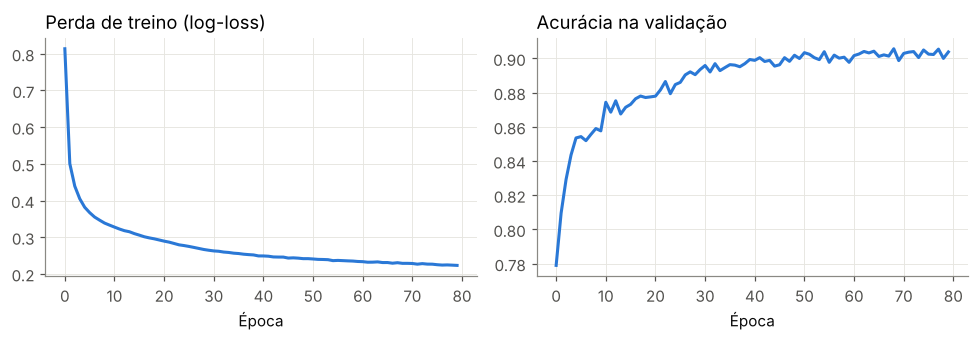

In [6]:
MODELOS = ["MLP", "RF"] if ALGORITMO == "AMBOS" else [ALGORITMO]
modelos, tempos_treino = {}, {}
for m in MODELOS:
    t0 = time.time()
    if m == "MLP":
        clf = MLPClassifier(**MLP_PARAMS).fit(X_tr_s, y_tr)
    else:
        clf = RandomForestClassifier(**RF_PARAMS).fit(X_tr, y_tr)
    tempos_treino[m] = time.time() - t0
    modelos[m] = clf
    extra = f" | épocas={clf.n_iter_}" if m == "MLP" else ""
    print(f"[{m}] treinado em {tempos_treino[m]:.1f}s{extra}")

if "MLP" in modelos:
    mlp = modelos["MLP"]
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].plot(mlp.loss_curve_, color=MODEL_COLOR["MLP"], lw=2); ax[0].set_title("Perda de treino (log-loss)", loc="left")
    ax[0].set_xlabel("Época")
    ax[1].plot(mlp.validation_scores_, color=MODEL_COLOR["MLP"], lw=2); ax[1].set_title("Acurácia na validação", loc="left")
    ax[1].set_xlabel("Época"); fig.tight_layout(); salvar(fig, "fig02_mlp_curva_treino"); plt.show()

## §6 — Teste do IDS: detecção de tráfego anômalo
O IDS classifica cada mensagem em uma das 9 classes. Para a função de **detecção de anomalia**, qualquer
predição diferente de `normal` gera um **alerta** (visão binária normal × ataque).

In [7]:
def latencia_unitaria(m, n=500):
    Xs = X_te_s if m == "MLP" else X_te
    clf = modelos[m]; amostras = Xs[np.random.RandomState(0).choice(len(Xs), n, replace=False)]
    if m == "RF": clf.set_params(n_jobs=1)   # evita overhead de threads em predição unitária
    clf.predict(amostras[:1])
    t0 = time.perf_counter()
    for i in range(n): clf.predict(amostras[i:i+1])
    lat = (time.perf_counter() - t0) / n * 1e3   # ms por mensagem
    if m == "RF": clf.set_params(n_jobs=-1)
    return lat

preds, res = {}, []
yb_te = (y_te != "normal").astype(int)
for m, clf in modelos.items():
    Xs = X_te_s if m == "MLP" else X_te
    t0 = time.perf_counter(); p = clf.predict(Xs); t_lote = time.perf_counter() - t0
    preds[m] = p
    pb = (p != "normal").astype(int)
    P, R, F, _ = precision_recall_fscore_support(y_te, p, average="macro", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(yb_te, pb).ravel()
    res.append({"modelo": m, "acuracia": accuracy_score(y_te, p), "precisao_macro": P, "recall_macro": R,
                "f1_macro": F, "f1_ponderado": f1_score(y_te, p, average="weighted"),
                "bin_acuracia": (tp + tn) / len(pb), "bin_precisao": tp / (tp + fp), "bin_recall_TPR": tp / (tp + fn),
                "bin_FPR": fp / (fp + tn), "bin_f1": 2 * tp / (2 * tp + fp + fn),
                "treino_s": tempos_treino[m], "lote_us_por_msg": t_lote / len(p) * 1e6,
                "unitaria_ms": latencia_unitaria(m)})
    print(f"\n===== {m} =====\n" + classification_report(y_te, p, labels=CLASSES, digits=4, zero_division=0))
resumo = pd.DataFrame(res).set_index("modelo")
display(resumo.round(4))


===== MLP =====
                        precision    recall  f1-score   support

                normal     0.7641    0.8388    0.7997     12000
              grayhole     0.6911    0.7062    0.6985      6000
            high_StNum     0.9998    0.9967    0.9982      6000
             injection     1.0000    0.9985    0.9992      6000
        inverse_replay     0.9851    0.9727    0.9789      6000
 masquerade_fake_fault     0.9883    0.9998    0.9940      6000
masquerade_fake_normal     0.9401    0.9552    0.9476      6000
    poisoned_high_rate     0.9977    0.9933    0.9955      6000
         random_replay     0.8989    0.6982    0.7859      6000

              accuracy                         0.8998     60000
             macro avg     0.9184    0.9066    0.9109     60000
          weighted avg     0.9029    0.8998    0.8997     60000




===== RF =====
                        precision    recall  f1-score   support

                normal     0.7822    0.8689    0.8233     12000
              grayhole     0.7201    0.6312    0.6727      6000
            high_StNum     1.0000    0.9997    0.9998      6000
             injection     1.0000    0.9988    0.9994      6000
        inverse_replay     0.9995    0.9950    0.9972      6000
 masquerade_fake_fault     0.9992    1.0000    0.9996      6000
masquerade_fake_normal     0.9973    0.9988    0.9981      6000
    poisoned_high_rate     1.0000    0.9998    0.9999      6000
         random_replay     0.9718    0.8800    0.9236      6000

              accuracy                         0.9241     60000
             macro avg     0.9411    0.9303    0.9349     60000
          weighted avg     0.9252    0.9241    0.9237     60000



,acuracia,precisao_macro,recall_macro,f1_macro,f1_ponderado,bin_acuracia,bin_precisao,bin_recall_TPR,bin_FPR,bin_f1,treino_s,lote_us_por_msg,unitaria_ms
modelo,,,,,,,,,,,,,
MLP,0.8998,0.9184,0.9066,0.9109,0.8997,0.9160,0.9587,0.9353,0.1612,0.9468,63.7707,2.6836,0.2047
RF,0.9241,0.9411,0.9303,0.9349,0.9237,0.9254,0.9663,0.9395,0.1311,0.9527,23.9611,8.7184,5.2513


## §7 — Matrizes de confusão

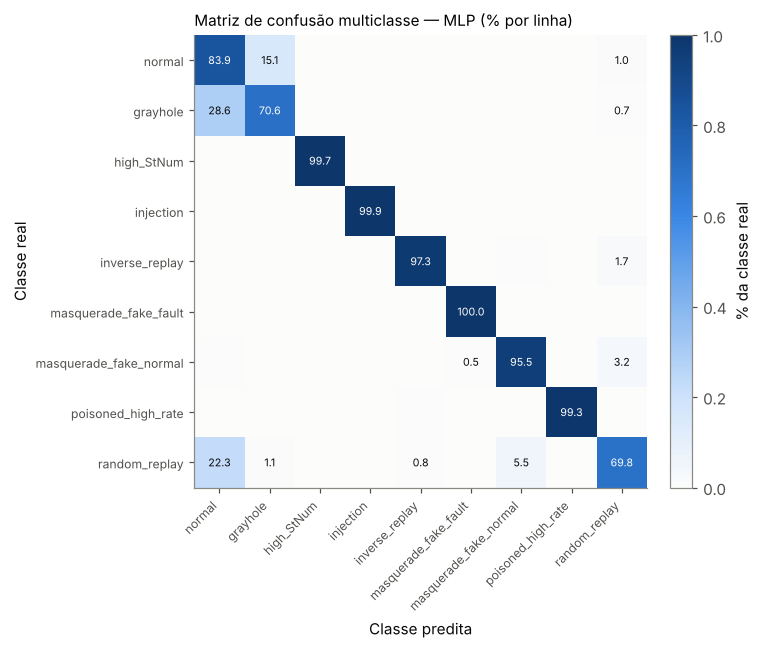

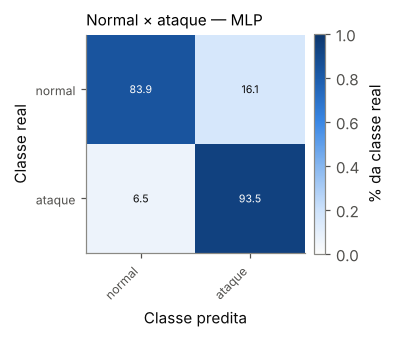

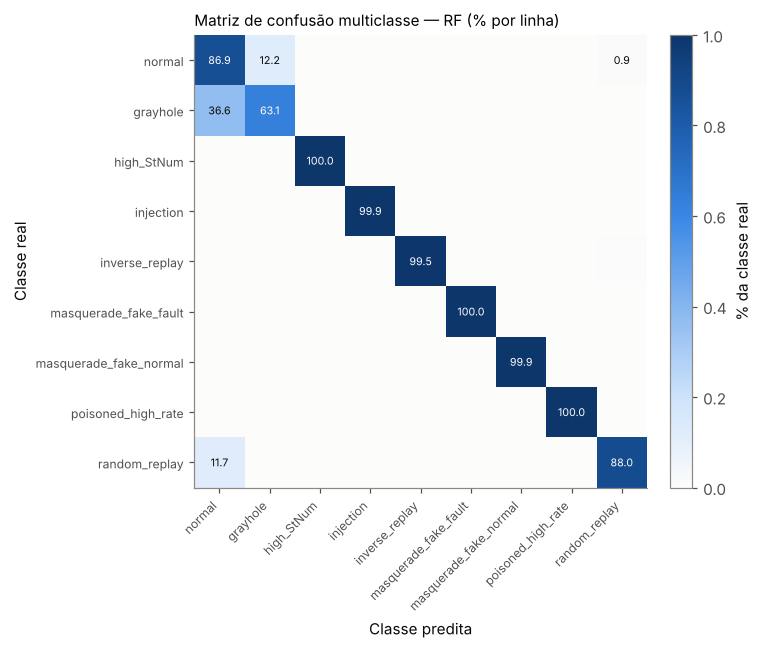

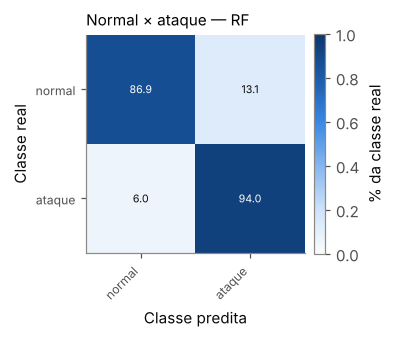

In [8]:
def plot_cm(cm, labels, titulo, nome, norm=True):
    cmn = cm / cm.sum(axis=1, keepdims=True) if norm else cm
    fig, ax = plt.subplots(figsize=(7.2, 6) if len(labels) > 2 else (3.6, 3.2))
    im = ax.imshow(cmn, cmap=SEQ, vmin=0, vmax=1 if norm else None)
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = cmn[i, j]
            if v >= 0.005 or i == j:
                txt = f"{v*100:.1f}" if norm else f"{int(v)}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=7, color="#fcfcfb" if v > 0.55 else "#0b0b0b")
    ax.set_xlabel("Classe predita"); ax.set_ylabel("Classe real"); ax.grid(False)
    ax.set_title(titulo, loc="left", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="% da classe real" if norm else "mensagens")
    fig.tight_layout(); salvar(fig, nome); plt.show()

cms = {}
for m, p in preds.items():
    cm = confusion_matrix(y_te, p, labels=CLASSES); cms[m] = cm
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(f"{OUT_DAT}/matriz_confusao_{m}.csv")
    plot_cm(cm, CLASSES, f"Matriz de confusão multiclasse — {m} (% por linha)", f"fig03_cm_multiclasse_{m}")
    cmb = confusion_matrix(yb_te, (p != "normal").astype(int))
    pd.DataFrame(cmb, index=["normal", "ataque"], columns=["normal", "ataque"]).to_csv(f"{OUT_DAT}/matriz_confusao_binaria_{m}.csv")
    plot_cm(cmb, ["normal", "ataque"], f"Normal × ataque — {m}", f"fig04_cm_binaria_{m}")

## §8 — Tráfego anômalo detectado por classe de ataque
Para cada classe de ataque: total de mensagens no teste, quantas foram **sinalizadas como anômalas**
(qualquer classe ≠ normal) e quantas foram **atribuídas ao ataque correto**.

modelo,MLP,RF
classe,,
grayhole,71.38,63.42
high_StNum,99.98,100.00
injection,99.98,99.98
inverse_replay,99.65,99.97
masquerade_fake_fault,100.00,100.00
masquerade_fake_normal,99.53,99.97
normal,16.12,13.11
poisoned_high_rate,100.00,100.00
random_replay,77.68,88.27


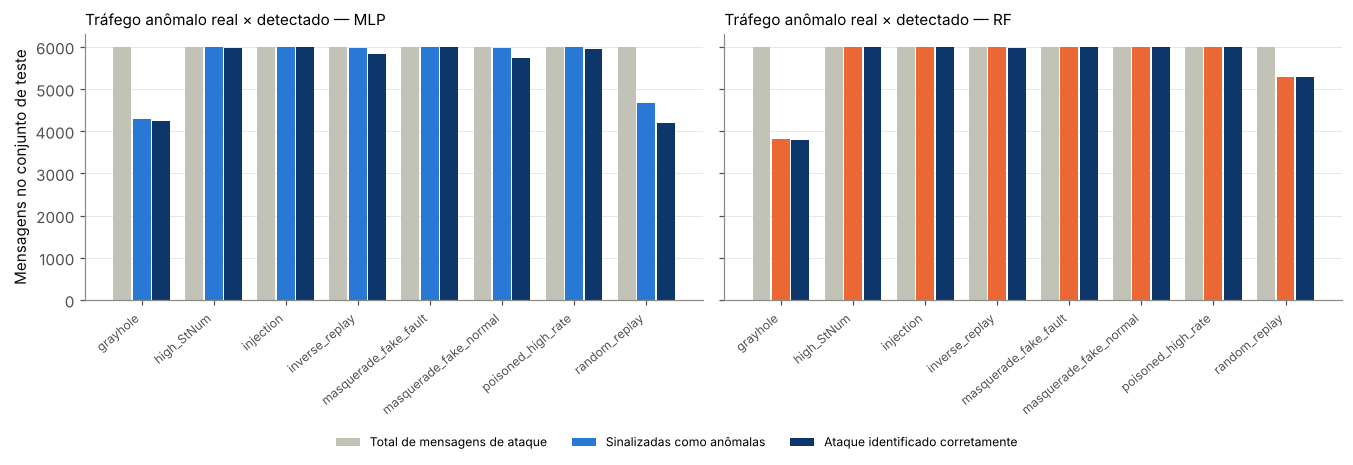

In [9]:
linhas = []
for m, p in preds.items():
    for a in ATTACKS:
        msk = y_te == a
        linhas.append({"modelo": m, "classe": a, "total": int(msk.sum()),
                       "detectado_anomalo": int((p[msk] != "normal").sum()),
                       "classificado_correto": int((p[msk] == a).sum())})
    msk = y_te == "normal"
    linhas.append({"modelo": m, "classe": "normal", "total": int(msk.sum()),
                   "detectado_anomalo": int((p[msk] != "normal").sum()), "classificado_correto": int((p[msk] == "normal").sum())})
det = pd.DataFrame(linhas)
det["taxa_deteccao_%"] = 100 * det["detectado_anomalo"] / det["total"]
det.to_csv(f"{OUT_DAT}/deteccao_por_classe.csv", index=False)
display(det.pivot(index="classe", columns="modelo", values="taxa_deteccao_%").round(2))

fig, axes = plt.subplots(1, len(preds), figsize=(6.2 * len(preds), 4), sharey=True, squeeze=False)
for ax, m in zip(axes[0], preds):
    d = det[(det.modelo == m) & (det.classe != "normal")].set_index("classe").reindex(ATTACKS)
    xx = np.arange(len(ATTACKS)); wdt = 0.27
    ax.bar(xx - wdt, d["total"], wdt * 0.92, color="#c3c2b7", label="Total de mensagens de ataque")
    ax.bar(xx, d["detectado_anomalo"], wdt * 0.92, color=MODEL_COLOR[m], label="Sinalizadas como anômalas")
    ax.bar(xx + wdt, d["classificado_correto"], wdt * 0.92, color="#0d366b", label="Ataque identificado corretamente")
    ax.set_xticks(xx); ax.set_xticklabels(ATTACKS, rotation=40, ha="right", fontsize=8)
    ax.set_title(f"Tráfego anômalo real × detectado — {m}", loc="left", fontsize=10); ax.grid(axis="x", visible=False)
axes[0][0].set_ylabel("Mensagens no conjunto de teste")
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(); salvar(fig, "fig05_deteccao_por_classe"); plt.show()

## §9 — Falhas de segurança do GOOSE exploradas e detectadas
Cada ataque do ERENO explora uma lacuna de projeto do GOOSE (IEC 61850-8-1), que é transmitido em *multicast*
na camada 2, sem autenticação nem cifragem quando o IEC 62351-6 não está implantado. O gráfico agrega as
detecções por **falha de segurança**, com os segmentos coloridos por ataque — no mesmo formato da matriz
regras × ataques do SBRC 2026.

total  detectado  \
modelo falha                                                                  
MLP    F1 · Sem autenticação de origem (falsificação d...  12000      11972   
       F2 · Sem integridade da mensagem (injeção de qu...   6000       5999   
       F3 · Sem proteção anti-replay (reenvio de quadr...  12000      10640   
       F4 · Sem validação de stNum/sqNum e de taxa (en...  12000      11999   
       F5 · Sem garantia de entrega (descarte seletivo...   6000       4283   
RF     F1 · Sem autenticação de origem (falsificação d...  12000      11998   
       F2 · Sem integridade da mensagem (injeção de qu...   6000       5999   
       F3 · Sem proteção anti-replay (reenvio de quadr...  12000      11294   
       F4 · Sem validação de stNum/sqNum e de taxa (en...  12000      12000   
       F5 · Sem garantia de entrega (descarte seletivo...   6000       3805   

                                                           cobertura_pct  
modelo falha                                                              
MLP    F1 · Sem autenticação de origem (falsificação d...          99.77  
       F2 · Sem integridade da mensagem (injeção de qu...          99.98  
       F3 · Sem proteção anti-replay (reenvio de quadr...          88.67  
       F4 · Sem validação de stNum/sqNum e de taxa (en...          99.99  
       F5 · Sem garantia de entrega (descarte seletivo...          71.38  
RF     F1 · Sem autenticação de origem (falsificação d...          99.98  
       F2 · Sem integridade da mensagem (injeção de qu...          99.98  
       F3 · Sem proteção anti-replay (reenvio de quadr...          94.12  
       F4 · Sem validação de stNum/sqNum e de taxa (en...         100.00  
       F5 · Sem garantia de entrega (descarte seletivo...          63.42

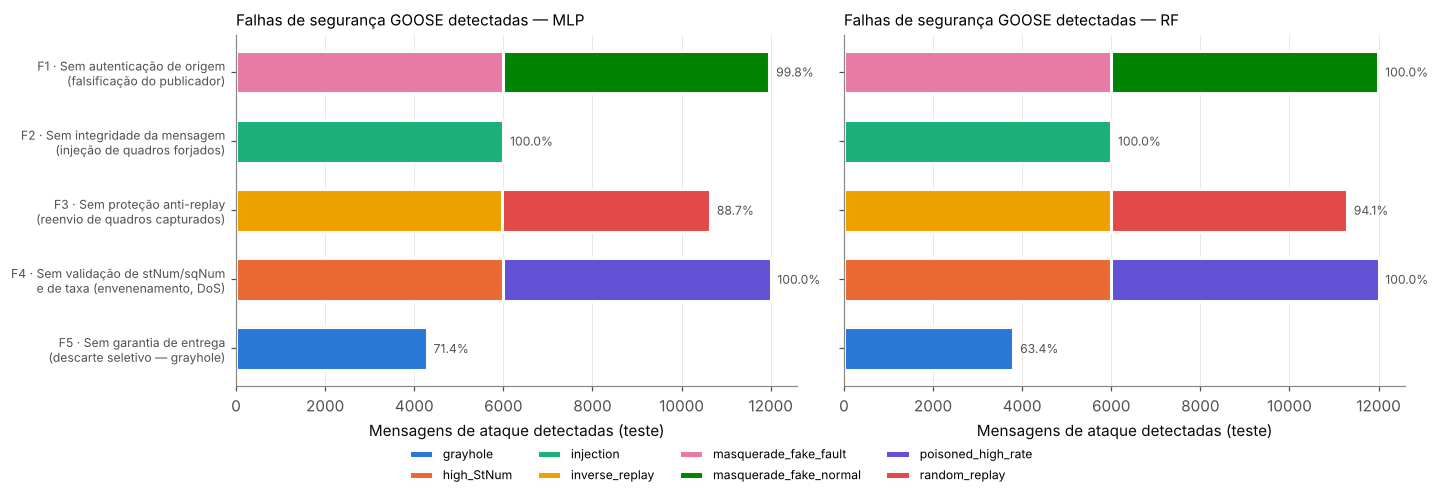

In [10]:
FALHAS = {
    "F1 · Sem autenticação de origem\n(falsificação do publicador)": ["masquerade_fake_fault", "masquerade_fake_normal"],
    "F2 · Sem integridade da mensagem\n(injeção de quadros forjados)": ["injection"],
    "F3 · Sem proteção anti-replay\n(reenvio de quadros capturados)": ["inverse_replay", "random_replay"],
    "F4 · Sem validação de stNum/sqNum\ne de taxa (envenenamento, DoS)": ["high_StNum", "poisoned_high_rate"],
    "F5 · Sem garantia de entrega\n(descarte seletivo — grayhole)": ["grayhole"],
}
tab_falhas = []
for m in preds:
    d = det[det.modelo == m].set_index("classe")
    for f, ats in FALHAS.items():
        for a in ats:
            tab_falhas.append({"modelo": m, "falha": f.replace("\n", " "), "ataque": a, "total": d.loc[a, "total"],
                               "detectado": d.loc[a, "detectado_anomalo"]})
tab_falhas = pd.DataFrame(tab_falhas); tab_falhas.to_csv(f"{OUT_DAT}/falhas_goose_detectadas.csv", index=False)
display(tab_falhas.groupby(["modelo", "falha"])[["total", "detectado"]].sum()
        .assign(cobertura_pct=lambda t: (100 * t.detectado / t.total).round(2)))

fig, axes = plt.subplots(1, len(preds), figsize=(6.6 * len(preds), 4.2), sharey=True, squeeze=False)
for ax, m in zip(axes[0], preds):
    d = det[det.modelo == m].set_index("classe"); ylab = list(FALHAS)[::-1]
    for yi, f in enumerate(ylab):
        left = 0
        for a in FALHAS[f]:
            v = d.loc[a, "detectado_anomalo"]
            ax.barh(yi, v, left=left, color=PALETTE[a], height=0.62, edgecolor="#fcfcfb", linewidth=2,
                    label=a if (yi, a) else None)
            left += v
        tot = sum(d.loc[a, "total"] for a in FALHAS[f])
        ax.text(left + 150, yi, f"{100*left/tot:.1f}%", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(range(len(ylab))); ax.set_yticklabels(ylab, fontsize=8)
    ax.set_xlabel("Mensagens de ataque detectadas (teste)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"Falhas de segurança GOOSE detectadas — {m}", loc="left", fontsize=10)
h, l = axes[0][0].get_legend_handles_labels(); uniq = dict(zip(l, h))
fig.legend([uniq[a] for a in ATTACKS], ATTACKS, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); salvar(fig, "fig06_falhas_goose"); plt.show()

## §10 — Comparativo MLP × Random Forest

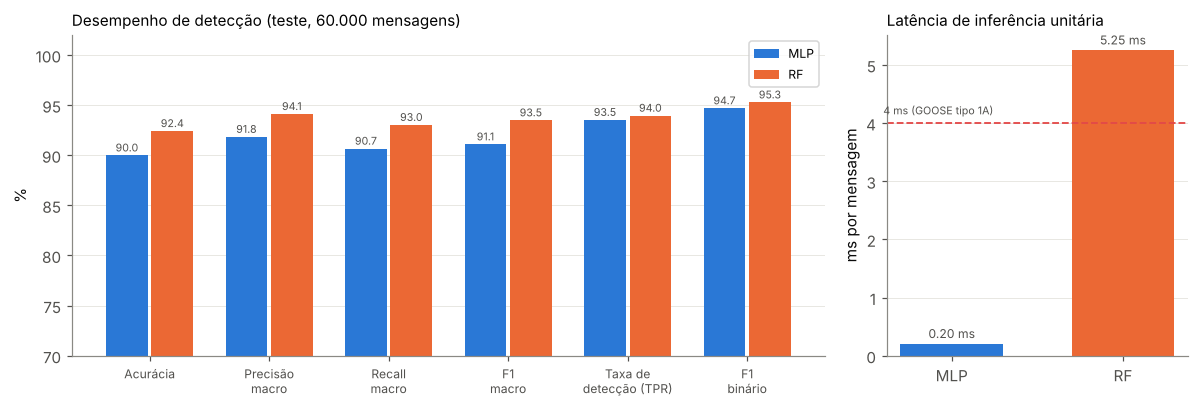

,MLP,RF
normal,79.97,82.33
grayhole,69.85,67.27
high_StNum,99.82,99.98
injection,99.92,99.94
inverse_replay,97.89,99.72
masquerade_fake_fault,99.40,99.96
masquerade_fake_normal,94.76,99.81
poisoned_high_rate,99.55,99.99
random_replay,78.59,92.36


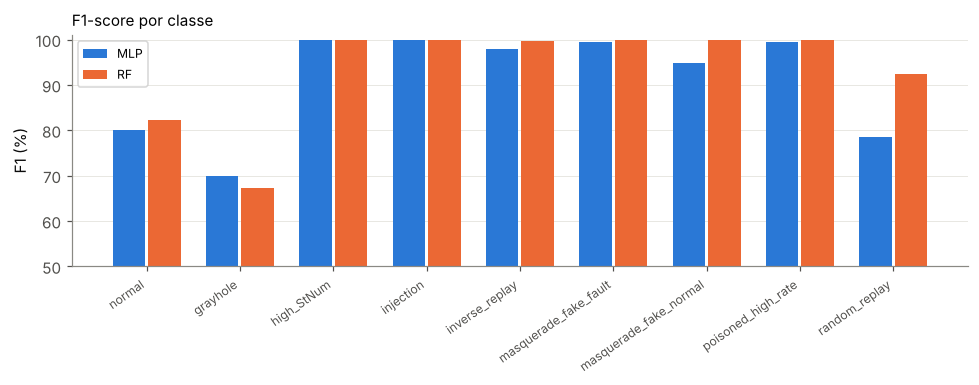

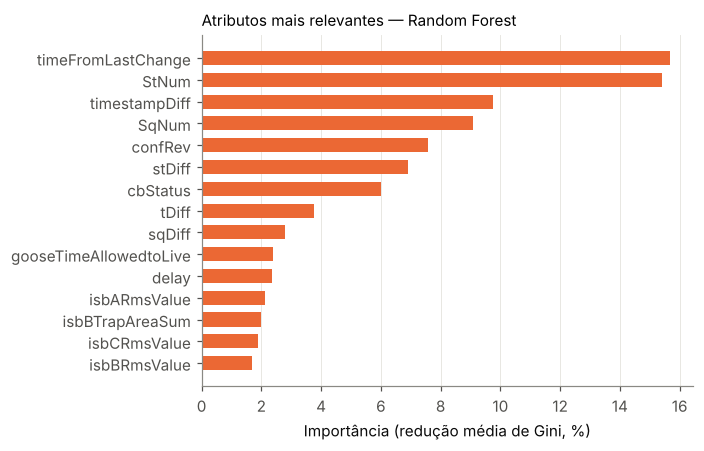

In [11]:
if len(modelos) == 2:
    met = ["acuracia", "precisao_macro", "recall_macro", "f1_macro", "bin_recall_TPR", "bin_f1"]
    nomes = ["Acurácia", "Precisão\nmacro", "Recall\nmacro", "F1\nmacro", "Taxa de\ndetecção (TPR)", "F1\nbinário"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 1.2]})
    xx = np.arange(len(met)); wdt = 0.38
    for k, m in enumerate(["MLP", "RF"]):
        vals = resumo.loc[m, met].values * 100
        ax[0].bar(xx + (k - 0.5) * wdt, vals, wdt * 0.92, color=MODEL_COLOR[m], label=m)
        for x_, v in zip(xx + (k - 0.5) * wdt, vals): ax[0].text(x_, v + 0.4, f"{v:.1f}", ha="center", fontsize=7, color="#52514e")
    ax[0].set_xticks(xx); ax[0].set_xticklabels(nomes, fontsize=8); ax[0].set_ylim(70, 102)
    ax[0].set_ylabel("%"); ax[0].legend(fontsize=8); ax[0].grid(axis="x", visible=False)
    ax[0].set_title("Desempenho de detecção (teste, 60.000 mensagens)", loc="left", fontsize=10)
    lat = resumo["unitaria_ms"]
    ax[1].bar(["MLP", "RF"], lat.values, color=[MODEL_COLOR["MLP"], MODEL_COLOR["RF"]], width=0.6)
    ax[1].axhline(4, color="#e34948", lw=1.2, ls="--"); ax[1].text(-0.4, 4.15, "4 ms (GOOSE tipo 1A)", ha="left", fontsize=7, color="#52514e")
    for i, v in enumerate(lat.values): ax[1].text(i, v + 0.1, f"{v:.2f} ms", ha="center", fontsize=8, color="#52514e")
    ax[1].set_ylabel("ms por mensagem"); ax[1].set_title("Latência de inferência unitária", loc="left", fontsize=10)
    ax[1].grid(axis="x", visible=False); fig.tight_layout(); salvar(fig, "fig07_comparativo_mlp_rf"); plt.show()

    # F1 por classe
    f1c = pd.DataFrame({m: f1_score(y_te, preds[m], labels=CLASSES, average=None) for m in modelos}, index=CLASSES)
    f1c.to_csv(f"{OUT_DAT}/f1_por_classe.csv"); display((f1c * 100).round(2))
    fig, ax = plt.subplots(figsize=(9, 3.6)); xx = np.arange(len(CLASSES))
    for k, m in enumerate(["MLP", "RF"]):
        ax.bar(xx + (k - 0.5) * wdt, f1c[m] * 100, wdt * 0.92, color=MODEL_COLOR[m], label=m)
    ax.set_xticks(xx); ax.set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=8); ax.set_ylim(50, 101)
    ax.set_ylabel("F1 (%)"); ax.legend(fontsize=8); ax.grid(axis="x", visible=False)
    ax.set_title("F1-score por classe", loc="left", fontsize=10); fig.tight_layout(); salvar(fig, "fig08_f1_por_classe"); plt.show()

if "RF" in modelos:
    imp = pd.Series(modelos["RF"].feature_importances_, index=FEATURES).sort_values(ascending=False)
    imp.to_csv(f"{OUT_DAT}/importancia_atributos_RF.csv")
    top = imp.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    ax.barh(top.index, top.values * 100, color=MODEL_COLOR["RF"], height=0.65)
    ax.set_xlabel("Importância (redução média de Gini, %)"); ax.grid(axis="y", visible=False)
    ax.set_title("Atributos mais relevantes — Random Forest", loc="left", fontsize=10)
    fig.tight_layout(); salvar(fig, "fig09_importancia_rf"); plt.show()

### §10.1 — Ablação: o que as medidas elétricas acrescentam?
Treina o Random Forest na mesma divisão com os dois conjuntos de atributos: só cabeçalho GOOSE e derivados
(19, os campos disponíveis para as regras e para um *switch*) e o conjunto completo (37).

In [12]:
abl = []
for nome, cols in {"protocolo (19)": PROTOCOLO, "protocolo_eletrico (37)": [c for c in num_cols if c not in ABSOLUTOS]}.items():
    Xa = df[cols].fillna(0.0).values
    rf_a = RandomForestClassifier(**RF_PARAMS).fit(Xa[idx_tr], y_tr); pa = rf_a.predict(Xa[idx_te])
    tn, fp, fn, tp = confusion_matrix(yb_te, (pa != "normal").astype(int)).ravel()
    f1c_a = f1_score(y_te, pa, labels=CLASSES, average=None)
    abl.append({"atributos": nome, "acuracia": accuracy_score(y_te, pa), "f1_macro": f1_score(y_te, pa, average="macro"),
                "TPR": tp / (tp + fn), "FPR": fp / (fp + tn), **{f"f1_{c}": v for c, v in zip(CLASSES, f1c_a)}})
abl = pd.DataFrame(abl).set_index("atributos"); abl.to_csv(f"{OUT_DAT}/ablacao_atributos_RF.csv")
display((abl * 100).round(2).T)

atributos,protocolo (19),protocolo_eletrico (37)
acuracia,89.96,92.41
f1_macro,91.36,93.49
TPR,91.88,93.95
FPR,16.37,13.11
f1_normal,77.39,82.33
f1_grayhole,67.57,67.27
f1_high_StNum,99.99,99.98
f1_injection,100.00,99.94
f1_inverse_replay,99.77,99.72
f1_masquerade_fake_fault,97.16,99.96


## §11 — IDS híbrido: anomalia (rede neural) + assinatura (regras LLM do SBRC 2026)
As regras de `rules_llm_sbrc2026.py` foram geradas pelo pipeline *From Red Flags to Detection Rules* (SBRC 2026).
Aqui elas são aplicadas ao **mesmo conjunto de teste** e combinadas com o modelo de anomalia por **OU lógico**:
um alerta é emitido se o modelo **ou** alguma regra sinalizar a mensagem. Duas fusões são avaliadas: **OU com todas as regras** e **OU seletivo**, que usa apenas
as regras cuja taxa de falso positivo em tráfego normal, medida no **treino**, é ≤ 0,5%. Esta é a base da arquitetura híbrida
proposta (assinatura para ataques conhecidos e interpretáveis; anomalia para o que as regras não cobrem).

22 regras LLM carregadas de rules_llm_sbrc2026.py


Regras selecionadas no treino (FPR em 'normal' ≤ 0.5%): 16/22
    ['rule_grayhole_low_sqnum_stdiff', 'rule_high_StNum_stnum_stdiff', 'rule_high_StNum_time_sqnum', 'rule_injection_seq_state', 'rule_inverse_replay_seq_state', 'rule_inverse_replay_state_jump_time', 'rule_masquerade_fake_fault_stdiff_tdiff', 'rule_masquerade_fake_fault_stnum_sqdiff', 'rule_masquerade_fake_fault_tdiff_timestamp', 'rule_masquerade_fake_normal_stnum_sqdiff', 'rule_masquerade_fake_normal_stnum_stdiff', 'rule_poisoned_high_rate_time_anomaly', 'rule_random_replay_a', 'rule_random_replay_b', 'rule_random_replay_c', 'rule_random_replay_d']


,TPR,FPR,precisao,f1,acuracia
Regras LLM (todas),32.58,5.01,96.30,48.69,45.06
Regras LLM (selecionadas),29.57,1.26,98.95,45.53,43.40
MLP,93.53,16.12,95.87,94.68,91.60
Híbrido OU (MLP + todas),93.66,20.81,94.74,94.20,90.77
Híbrido seletivo (MLP + selec.),93.63,17.21,95.61,94.61,91.46
RF,93.95,13.11,96.63,95.27,92.54
Híbrido OU (RF + todas),94.07,17.90,95.46,94.76,91.68
Híbrido seletivo (RF + selec.),94.04,14.26,96.35,95.18,92.38


Custo médio das regras (Python puro): 2.7 µs/mensagem


,Regras LLM (todas),Regras LLM (selecionadas),MLP,Híbrido OU (MLP + todas),Híbrido seletivo (MLP + selec.),RF,Híbrido OU (RF + todas),Híbrido seletivo (RF + selec.)
normal,5.01,1.26,16.12,20.81,17.21,13.11,17.90,14.26
grayhole,1.98,0.62,71.38,72.03,71.82,63.42,64.18,63.98
high_StNum,92.38,92.32,99.98,100.00,100.00,100.00,100.00,100.00
injection,22.80,21.12,99.98,99.98,99.98,99.98,100.00,100.00
inverse_replay,11.57,0.87,99.65,99.65,99.65,99.97,99.97,99.97
masquerade_fake_fault,5.07,3.22,100.00,100.00,100.00,100.00,100.00,100.00
masquerade_fake_normal,28.12,25.17,99.53,99.60,99.57,99.97,99.97,99.97
poisoned_high_rate,93.03,91.68,100.00,100.00,100.00,100.00,100.00,100.00
random_replay,5.72,1.58,77.68,78.02,78.02,88.27,88.43,88.43


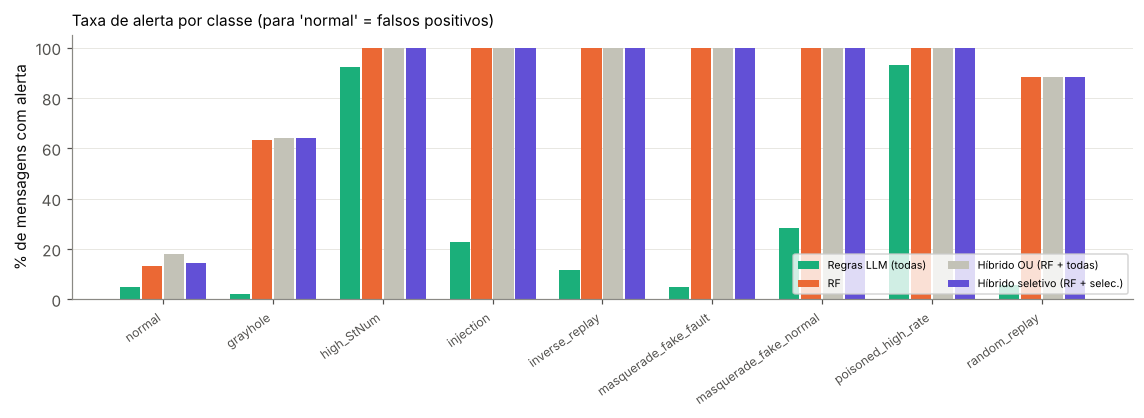

In [13]:
hib = None
if USAR_REGRAS_LLM and os.path.exists(ARQUIVO_REGRAS):
    spec = importlib.util.spec_from_file_location("regras_llm", ARQUIVO_REGRAS)
    regras_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(regras_mod)
    regras = [f for n, f in inspect.getmembers(regras_mod, inspect.isfunction) if n.startswith("rule_")]
    print(f"{len(regras)} regras LLM carregadas de {ARQUIVO_REGRAS}")
    pacotes = df.iloc[idx_te][num_cols].fillna(0.0).to_dict("records")
    t0 = time.perf_counter()
    alerta_regra = np.array([any(r(pk) for r in regras) for pk in pacotes], dtype=int)
    t_reg = (time.perf_counter() - t0) / len(pacotes) * 1e6
    disparos = pd.DataFrame({r.__name__: [int(r(pk)) for pk in pacotes] for r in regras})
    disparos["classe"] = y_te
    disparos.groupby("classe").sum().T.to_csv(f"{OUT_DAT}/matriz_regras_ataques_teste.csv")

    def met_bin(pb):
        tn, fp, fn, tp = confusion_matrix(yb_te, pb).ravel()
        return dict(TPR=tp / (tp + fn), FPR=fp / (fp + tn), precisao=tp / (tp + fp), f1=2 * tp / (2 * tp + fp + fn),
                    acuracia=(tp + tn) / len(pb))
    # Seleção de regras de alta precisão usando SOMENTE o treino (sem vazamento do teste)
    rs = np.random.RandomState(RANDOM_STATE); amostra_tr = rs.choice(idx_tr, 30000, replace=False)
    pac_tr = df.iloc[amostra_tr][num_cols].fillna(0.0).to_dict("records"); y_amostra = df["class"].values[amostra_tr]
    sel = []
    for r in regras:
        f = np.array([r(pk) for pk in pac_tr], dtype=bool)
        fpr_n = f[y_amostra == "normal"].mean(); cob = f[y_amostra != "normal"].mean()
        if fpr_n <= LIMIAR_FPR_REGRA and cob > 0: sel.append(r)
    print(f"Regras selecionadas no treino (FPR em 'normal' ≤ {LIMIAR_FPR_REGRA*100:.1f}%): {len(sel)}/{len(regras)}")
    print("   ", [r.__name__ for r in sel])
    alerta_sel = disparos[[r.__name__ for r in sel]].max(axis=1).values if sel else np.zeros(len(y_te), int)

    comp = {"Regras LLM (todas)": alerta_regra, "Regras LLM (selecionadas)": alerta_sel}
    for m, p in preds.items():
        comp[m] = (p != "normal").astype(int)
        comp[f"Híbrido OU ({m} + todas)"] = np.maximum(comp[m], alerta_regra)
        comp[f"Híbrido seletivo ({m} + selec.)"] = np.maximum(comp[m], alerta_sel)
    hib = pd.DataFrame({k: met_bin(v) for k, v in comp.items()}).T
    hib.to_csv(f"{OUT_DAT}/hibrido_metricas_binarias.csv"); display((hib * 100).round(2))
    print(f"Custo médio das regras (Python puro): {t_reg:.1f} µs/mensagem")

    rec = pd.DataFrame({k: [v[y_te == c].mean() * 100 for c in CLASSES] for k, v in comp.items()}, index=CLASSES)
    rec.to_csv(f"{OUT_DAT}/hibrido_taxa_alerta_por_classe.csv"); display(rec.round(2))
    base = "RF" if "RF" in preds else list(preds)[0]
    cols = ["Regras LLM (todas)", base, f"Híbrido OU ({base} + todas)", f"Híbrido seletivo ({base} + selec.)"]
    cores = [MODEL_COLOR["Regras LLM"], MODEL_COLOR[base], "#c3c2b7", MODEL_COLOR["Híbrido"]]
    fig, ax = plt.subplots(figsize=(10.5, 3.9)); xx = np.arange(len(CLASSES)); wdt = 0.2
    for k, (c, cor) in enumerate(zip(cols, cores)):
        ax.bar(xx + (k - 1.5) * wdt, rec[c], wdt * 0.92, color=cor, label=c)
    ax.set_xticks(xx); ax.set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("% de mensagens com alerta"); ax.legend(fontsize=7, ncol=2, loc="lower right")
    ax.grid(axis="x", visible=False)
    ax.set_title("Taxa de alerta por classe (para 'normal' = falsos positivos)", loc="left", fontsize=10)
    fig.tight_layout(); salvar(fig, "fig10_hibrido_por_classe"); plt.show()
else:
    print("Regras LLM não encontradas — §11 ignorada.")

## §12 — Exportação

In [14]:
resumo.to_csv(f"{OUT_DAT}/resumo_metricas.csv")
meta = dict(dataset=DATASET, arquivo=path, algoritmo=ALGORITMO, atributos=CONJUNTO_ATRIBUTOS, n_atributos=len(FEATURES),
            features=FEATURES, n_treino=int(len(y_tr)), n_teste=int(len(y_te)), test_size=TEST_SIZE,
            random_state=RANDOM_STATE, mlp_params={k: str(v) for k, v in MLP_PARAMS.items()},
            rf_params={k: str(v) for k, v in RF_PARAMS.items()}, executado_em=STAMP,
            mlp_epocas=int(modelos["MLP"].n_iter_) if "MLP" in modelos else None)
json.dump(meta, open(f"{OUT_DAT}/metadados_experimento.json", "w"), indent=2, ensure_ascii=False)
print("Arquivos gerados:"); [print("  ", os.path.join(r, f)) for r, _, fs in os.walk("resultados") for f in sorted(fs)]

Arquivos gerados:
   resultados/figuras/fig01_distribuicao_classes.pdf
   resultados/figuras/fig01_distribuicao_classes.png
   resultados/figuras/fig02_mlp_curva_treino.pdf
   resultados/figuras/fig02_mlp_curva_treino.png
   resultados/figuras/fig03_cm_multiclasse_MLP.pdf
   resultados/figuras/fig03_cm_multiclasse_MLP.png
   resultados/figuras/fig03_cm_multiclasse_RF.pdf
   resultados/figuras/fig03_cm_multiclasse_RF.png
   resultados/figuras/fig04_cm_binaria_MLP.pdf
   resultados/figuras/fig04_cm_binaria_MLP.png
   resultados/figuras/fig04_cm_binaria_RF.pdf
   resultados/figuras/fig04_cm_binaria_RF.png
   resultados/figuras/fig05_deteccao_por_classe.pdf
   resultados/figuras/fig05_deteccao_por_classe.png
   resultados/figuras/fig06_falhas_goose.pdf
   resultados/figuras/fig06_falhas_goose.png
   resultados/figuras/fig07_comparativo_mlp_rf.pdf
   resultados/figuras/fig07_comparativo_mlp_rf.png
   resultados/figuras/fig08_f1_por_classe.pdf
   resultados/figuras/fig08_f1_por_classe.png
  

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]